# code_150 · Cross-series learning, patches and forecasting context

**Book:** section29.1. Restart and run all cells in the pinned environment. All generated inputs, helpers and fitted teaching models are internal; no files, downloads, credentials or GPU are needed. Use the [quickstart](../README.md), [guide](../CHAPTER_29_GUIDE.md), [execution evidence](../CHAPTER_29_EXECUTION.md), [assets](../CHAPTER_29_ASSETS.md) and [registry](../CODE_EXAMPLES.md#code_150). Prerequisites: arrays, forecasting boundaries and Chapters24–26. Allow one minute for execution and30–60minutes to interpret the controls.

All task records are locally generated teaching inputs, not field observations. A generated series or equation family is not evidence of operational validity. Named forecasting checkpoints are identified explicitly; own shared forecasters and learned stencils are not Poseidon, Aurora, TimesFM or Chronos reproductions. Every fit, selected transformation, label budget and final assessment has a declared boundary. CPU float32 neural computations use one thread; numerical references use float64 where appropriate. The literature cutoff is18October2026; access21October2026 does not extend it.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np,scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(3750);torch.use_deterministic_algorithms(True)
START=time.perf_counter();SEED=3750;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 3750


<a id="cross-series-pretraining"></a>
 ## Train shared weights on whole source series
 An own small patch predictor is pretrained on160 independently generated sensor series. Twenty-four other series select its checkpoint;24final series and24changed-period series assess the frozen weights. Each series has256points. The model receives64history values as8patches of8values and predicts12steps. A context-only mean and scale normalize each window. Shared patch embeddings feed an order-preserving flattened head; this is an actual small shared forecaster, not a named foundation checkpoint. Source windows have origins96/112/128/144/160, and source-series identities never enter development or final selection.1500Adam updates at0.002 use32windows per update, with development checks every100updates. Final origins192/216are assessed separately from source fitting. Local ridge autoregression and a seasonal repeat receive only each admitted history; declared period metadata goes to the seasonal control.


,cohort,model,MAE,series,origins_per_series
0,Source-period family,Scratch shared,0.761355,24,2
1,Source-period family,Frozen pretrained,0.112015,24,2
2,Source-period family,Local ridge AR,0.237036,24,2
3,Source-period family,Seasonal repeat,0.149444,24,2
4,Changed periods,Scratch shared,0.784972,24,2
5,Changed periods,Frozen pretrained,1.506708,24,2
6,Changed periods,Local ridge AR,0.235136,24,2
7,Changed periods,Seasonal repeat,0.158296,24,2


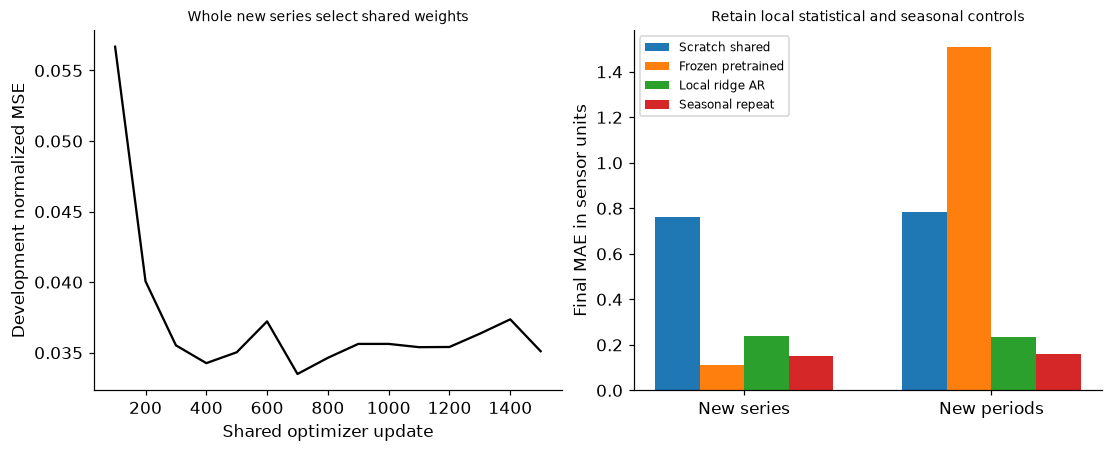

In [2]:
from sklearn.linear_model import Ridge
def collection(n,changed=False):
    records=[];periods=[]
    for _ in range(n):
        period=int(rng.choice([18,36] if changed else [12,24,48]));phase=rng.uniform(0,2*np.pi);amplitude=rng.uniform(.5,2);offset=rng.uniform(-3,3);trend=rng.uniform(-.006,.006);t=np.arange(256)
        y=offset+amplitude*np.sin(2*np.pi*t/period+phase)+.25*amplitude*np.cos(4*np.pi*t/period+phase)+trend*t+rng.normal(0,.12,256);records.append(y.astype(np.float32));periods.append(period)
    return np.array(records),np.array(periods)
source,source_period=collection(160);dev,dev_period=collection(24);final,final_period=collection(24);changed,changed_period=collection(24,True)
def windows(values,origins):
    x=np.array([row[o-64:o] for row in values for o in origins]);y=np.array([row[o:o+12] for row in values for o in origins]);mu=x.mean(1,keepdims=True);scale=np.maximum(x.std(1,keepdims=True),1e-4);return torch.tensor((x-mu)/scale),torch.tensor((y-mu)/scale),mu,scale
SX,SY,_,_=windows(source,[96,112,128,144,160]);DX,DY,_,_=windows(dev,[160,184])
class PatchForecaster(nn.Module):
    def __init__(self):super().__init__();self.embed=nn.Sequential(nn.Linear(8,16),nn.GELU());self.head=nn.Sequential(nn.Linear(128,48),nn.GELU(),nn.Linear(48,12))
    def forward(self,x):return self.head(self.embed(x.reshape(-1,8,8)).reshape(-1,128))
model=PatchForecaster();scratch=copy.deepcopy(model);optimizer=torch.optim.Adam(model.parameters(),lr=.002);best=np.inf;trace=[]
for step in range(1500):
    ids=torch.tensor(rng.choice(len(SX),32,replace=False));optimizer.zero_grad();loss=(model(SX[ids])-SY[ids]).square().mean();loss.backward();optimizer.step()
    if (step+1)%100==0:
        with torch.no_grad():score=float((model(DX)-DY).square().mean())
        trace.append((step+1,score))
        if score<best:best=score;best_step=step+1;state=copy.deepcopy(model.state_dict())
model.load_state_dict(state);model.eval()
def neural_predict(network,values,origins):
    x,_,mu,scale=windows(values,origins)
    with torch.no_grad():return network(x).numpy()*scale+mu
def local_predictions(values,periods,origins):
    autoreg=[];seasonal=[]
    for row,period in zip(values,periods):
        for origin in origins:
            ctx=row[origin-64:origin].astype(float);features=np.array([ctx[j-16:j] for j in range(16,64)]);fit=Ridge(alpha=1).fit(features,ctx[16:]);history=list(ctx);prediction=[]
            for h in range(12):value=float(fit.predict(np.array(history[-16:])[None])[0]);history.append(value);prediction.append(value)
            autoreg.append(prediction);seasonal.append(np.resize(ctx[-period:],12))
    return np.array(autoreg),np.array(seasonal)
origins=[192,216];rows=[];predictions={}
for cohort,values,periods in [('Source-period family',final,final_period),('Changed periods',changed,changed_period)]:
    truth=np.array([row[o:o+12] for row in values for o in origins]);ar,sn=local_predictions(values,periods,origins);predictors={'Scratch shared':neural_predict(scratch,values,origins),'Frozen pretrained':neural_predict(model,values,origins),'Local ridge AR':ar,'Seasonal repeat':sn};predictions[cohort]=predictors
    rows.extend({'cohort':cohort,'model':name,'MAE':float(np.mean(np.abs(pred-truth))),'series':len(values),'origins_per_series':2} for name,pred in predictors.items())
frozen_hash=hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in model.parameters())).hexdigest();intervened=final.copy();intervened[:,192:]+=1000;np.testing.assert_array_equal(neural_predict(model,intervened,[192]),neural_predict(model,final,[192]));assert frozen_hash==hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in model.parameters())).hexdigest()
# A fixed bin range loses amplitude information at saturation; normalization is fitted on context only.
original=final[0,128:192];normalized=(original-original.mean())/original.std();centres=np.linspace(-2,2,33);quantized=centres[np.abs(normalized[:,None]-centres).argmin(1)];scale_error=float(np.mean(np.abs((quantized*original.std()+original.mean())-original)))
RESULTS.update(source_series=160,development_series=24,final_series=24,changed_series=24,history_length=64,patch_length=8,horizon=12,source_windows=len(SX),pretraining_updates=1500,learning_rate=.002,selected_update=best_step,development_normalized_MSE=best,parameters=sum(p.numel() for p in model.parameters()),comparisons=rows,context_quantization_MAE=scale_error,future_intervention_max_difference=0.0,frozen_weights_unchanged=True);display(pd.DataFrame(rows))
fig,axes=plt.subplots(1,2,figsize=(10,4));h=np.array(trace);axes[0].plot(h[:,0],h[:,1],color='black');axes[0].set(xlabel='Shared optimizer update',ylabel='Development normalized MSE',title='Whole new series select shared weights');labels=['Source-period family','Changed periods'];names=list(predictions[labels[0]]);xx=np.arange(2)
for j,name in enumerate(names):axes[1].bar(xx+(j-1.5)*.18,[next(r['MAE'] for r in rows if r['cohort']==c and r['model']==name) for c in labels],width=.18,label=name)
axes[1].set(xticks=xx,xticklabels=['New series','New periods'],ylabel='Final MAE in sensor units',title='Retain local statistical and seasonal controls');axes[1].legend(fontsize=8);plt.show()


<a id="context-and-token-contracts"></a>
 ## Keep the observation clock and information boundary
 Normalization parameters come from each historical context, never from its withheld horizon. A64-value history at hourly cadence and at half-hourly cadence spans different physical time; equal tensor shapes do not make those inputs semantically equivalent. The separate quantization illustration uses33fixed centres on a normalized scale, unlike this continuous patch network. It exposes finite-bin approximation rather than claiming that all forecasting families tokenize scalar values. Source pretraining, new-target context and optional target fitting are different evidence lanes. Mutating all values at and after the forecast origin leaves the admitted prediction exactly unchanged. The own source generator's periods and smooth shape are a deliberately narrow prior; failures on changed periods remain visible.


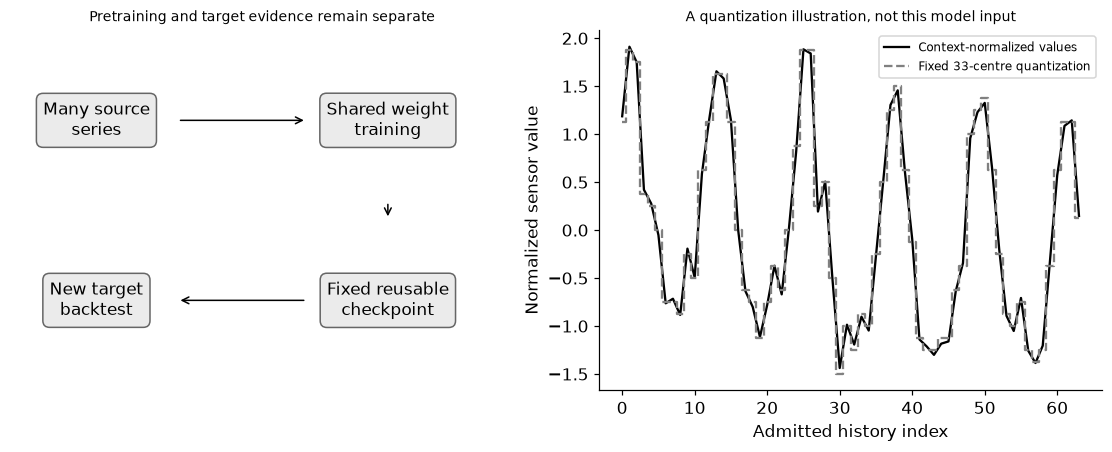

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));ax=axes[0];ax.axis('off');nodes=[(.17,.75,'Many source\nseries'),(.75,.75,'Shared weight\ntraining'),(.75,.25,'Fixed reusable\ncheckpoint'),(.17,.25,'New target\nbacktest')]
for xx,yy,label in nodes:ax.text(xx,yy,label,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'round,pad=.4','facecolor':'.92','edgecolor':'.4'})
for a,b in [(0,1),(1,2),(2,3)]:ax.annotate('',xy=nodes[b][:2],xytext=nodes[a][:2],xycoords='axes fraction',arrowprops={'arrowstyle':'->','shrinkA':55,'shrinkB':55})
ax.set_title('Pretraining and target evidence remain separate');axes[1].plot(np.arange(64),normalized,label='Context-normalized values',color='black');axes[1].step(np.arange(64),quantized,where='mid',linestyle='--',color='.5',label='Fixed 33-centre quantization');axes[1].set(xlabel='Admitted history index',ylabel='Normalized sensor value',title='A quantization illustration, not this model input');axes[1].legend(fontsize=8);plt.show()
assert min(r['MAE'] for r in rows)>=0 and len(trace)==15 and source.shape==(160,256)


In [4]:
summary={'example_id':'code_150','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual shared forecasting pretraining across independent generated series', 'context-only normalization and patch representation', 'whole-series model selection and final assessment', 'frozen checkpoint versus local autoregression and seasonal controls', 'scale quantization and causal context interventions'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual shared forecasting pretraining across independent generated series", "context-only normalization and patch representation", "whole-series model selection and final assessment", "frozen checkpoint versus local autoregression and seasonal controls", "scale quantization and causal context interventions"], "elapsed_seconds": 0.607, "example_id": "code_150", "hardware": "Darwin arm64 CPU", "results": {"changed_series": 24, "comparisons": [{"MAE": 0.761355459690094, "cohort": "Source-period family", "model": "Scratch shared", "origins_per_series": 2, "series": 24}, {"MAE": 0.11201539635658264, "cohort": "Source-period family", "model": "Frozen pretrained", "origins_per_series": 2, "series": 24}, {"MAE": 0.23703552478238624, "cohort": "Source-period family", "model": "Local ridge AR", "origins_per_series": 2, "series": 24}, {"MAE": 0.149443984130509, "cohort": "Source-period family", "model": "Seasonal repeat", "origins_per_series": 2,